# 2 · The ideal Brayton cycle and the turbojet

Lesson: [02](../docs/lessons/02-ideal-brayton-cycle.md) ·
Theory: [ideal Brayton cycle](../docs/brayton_cycle.md).

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt
from propulsion import plotting as P
from propulsion.flight import FlightCondition
from propulsion.units import FT, tsfc_to_lb_per_lbf_h

P.use_style()
np.set_printoptions(precision=4, suppress=True)
FL350 = FlightCondition.at_altitude(35000 * FT, 0.78, geopotential=True)
SLS = FlightCondition.sea_level_static()
from propulsion.brayton_cycle import (ideal_turbojet, optimum_compressor_pressure_ratio,
                                      ts_diagram, brayton_thermal_efficiency)
CRUISE = FlightCondition.at_altitude(11000.0, 0.8, geopotential=True)

## The worked example of Lesson 2

F/m0 = 920.9 N s/kg,  f = 0.02404,  TSFC = 26.10 mg/(N s) = 0.922 lb/(lbf h)
eta_T = 0.623, eta_P = 0.339, eta_O = 0.211
optimum pi_c = 21.70


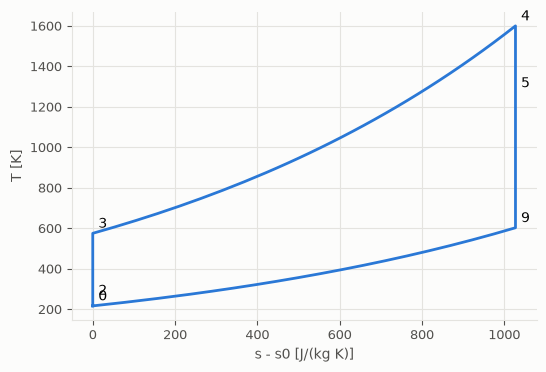

In [2]:
p = ideal_turbojet(CRUISE, pi_c=20.0, Tt4=1600.0)
print(f"F/m0 = {float(p.specific_thrust):.1f} N s/kg,  f = {float(p.f):.5f},  "
      f"TSFC = {float(p.tsfc)*1e6:.2f} mg/(N s) = {tsfc_to_lb_per_lbf_h(float(p.tsfc)):.3f} lb/(lbf h)")
print(f"eta_T = {float(p.eta_thermal):.3f}, eta_P = {float(p.eta_propulsive):.3f}, "
      f"eta_O = {float(p.eta_overall):.3f}")
print(f"optimum pi_c = {float(optimum_compressor_pressure_ratio(CRUISE, 1600.0)):.2f}")
labels, T, s, Tp, sp = ts_diagram(p)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(sp, Tp)
for k, x, y in zip(labels, s, T):
    ax.annotate(k, (x, y), xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("s - s0 [J/(kg K)]"); ax.set_ylabel("T [K]")
plt.show()

## Sweeps

Everything broadcasts: one call evaluates a whole grid of pressure ratios and temperatures.

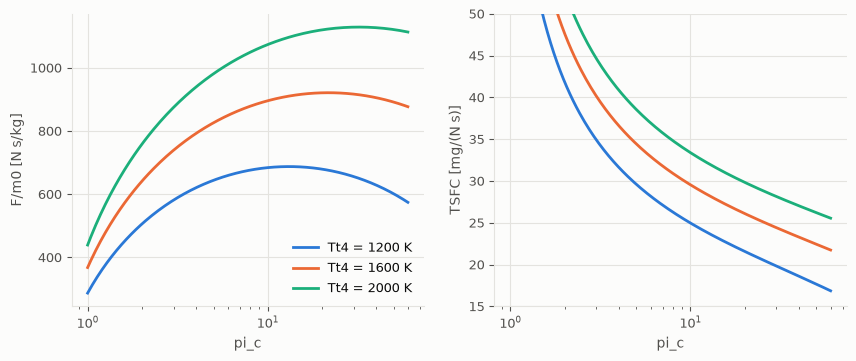

In [3]:
pi_c = np.geomspace(1.0, 60.0, 200)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for Tt4 in (1200.0, 1600.0, 2000.0):
    q = ideal_turbojet(CRUISE, pi_c, Tt4)
    axes[0].plot(pi_c, q.specific_thrust, label=f"Tt4 = {Tt4:.0f} K")
    axes[1].plot(pi_c, q.tsfc * 1e6)
for ax in axes:
    ax.set_xscale("log"); ax.set_xlabel("pi_c")
axes[0].set_ylabel("F/m0 [N s/kg]"); axes[1].set_ylabel("TSFC [mg/(N s)]"); axes[1].set_ylim(15, 50)
axes[0].legend(); plt.show()

## Fast flight needs less compression: the ramjet limit

In [4]:
for M0 in (0.0, 0.8, 2.0, 3.0):
    fc = FlightCondition.at_altitude(11000.0, M0, geopotential=True)
    print(f"M0 = {M0:3.1f}: optimum pi_c = {float(optimum_compressor_pressure_ratio(fc, 1600.0)):7.2f}")
print("closed Brayton efficiency at pi = 30:", round(float(brayton_thermal_efficiency(30.0)), 4))

M0 = 0.0: optimum pi_c =   33.09
M0 = 0.8: optimum pi_c =   21.70
M0 = 2.0: optimum pi_c =    4.23
M0 = 3.0: optimum pi_c =    0.90
closed Brayton efficiency at pi = 30: 0.6216
